In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

In [2]:
df = pd.read_csv('returns.csv')
df.head()

,return_id,order_item_id,return_date,return_reason,refund_amount,return_status
0,R0018,OI000526,21-Jan-2024,wrong item,18739.92,Approved
1,R0045,OI000620,11/12/2025,size issue,6474.73,APPROVED
2,R0044,OI000640,02-Apr-2024,Wrong Item,25783.29,Rejected
3,R0002,OI000546,18-Jun-2024,not as described,18753.51,approved
4,R0053,OI000045,03/21/2024,wrong item,NaN,Approved


In [3]:
df.shape

(68, 6)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 68 entries, 0 to 67
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   return_id      68 non-null     str    
 1   order_item_id  68 non-null     str    
 2   return_date    68 non-null     str    
 3   return_reason  68 non-null     str    
 4   refund_amount  64 non-null     float64
 5   return_status  68 non-null     str    
dtypes: float64(1), str(5)
memory usage: 3.3 KB


In [5]:
df.isnull().sum()

return_id        0
order_item_id    0
return_date      0
return_reason    0
refund_amount    4
return_status    0
dtype: int64

In [6]:
print(df.duplicated().sum())
print(df['return_id'].duplicated().sum())
print(df['order_item_id'].duplicated().sum())
df[df['return_id'].duplicated(keep=False)].sort_values('return_id')

3
3
3


,return_id,order_item_id,return_date,return_reason,refund_amount,return_status
3,R0002,OI000546,18-Jun-2024,not as described,18753.51,approved
56,R0002,OI000546,18-Jun-2024,not as described,18753.51,approved
14,R0029,OI000002,04-Jun-2024,Not as Described,41619.40,Approved
57,R0029,OI000002,04-Jun-2024,Not as Described,41619.40,Approved
1,R0045,OI000620,11/12/2025,size issue,6474.73,APPROVED
27,R0045,OI000620,11/12/2025,size issue,6474.73,APPROVED


In [7]:
print(df['return_reason'].value_counts())
print()
print(df['return_status'].value_counts())

return_reason
not as described    15
Size Issue          14
wrong item           8
Not as Described     6
Wrong Item           5
Defective            5
size issue           4
defective            4
DEFECTIVE            3
Wrong item           3
Damged               1
Name: count, dtype: int64

return_status
rejected    15
Approved    12
approved    12
APPROVED    11
Pending     10
Rejected     8
Name: count, dtype: int64


In [8]:
df['refund_amount'].describe()

count        64.000000
mean      35913.141719
std       28537.301370
min        3268.110000
25%       13849.055000
50%       22983.155000
75%       59420.045000
max      110787.580000
Name: refund_amount, dtype: float64

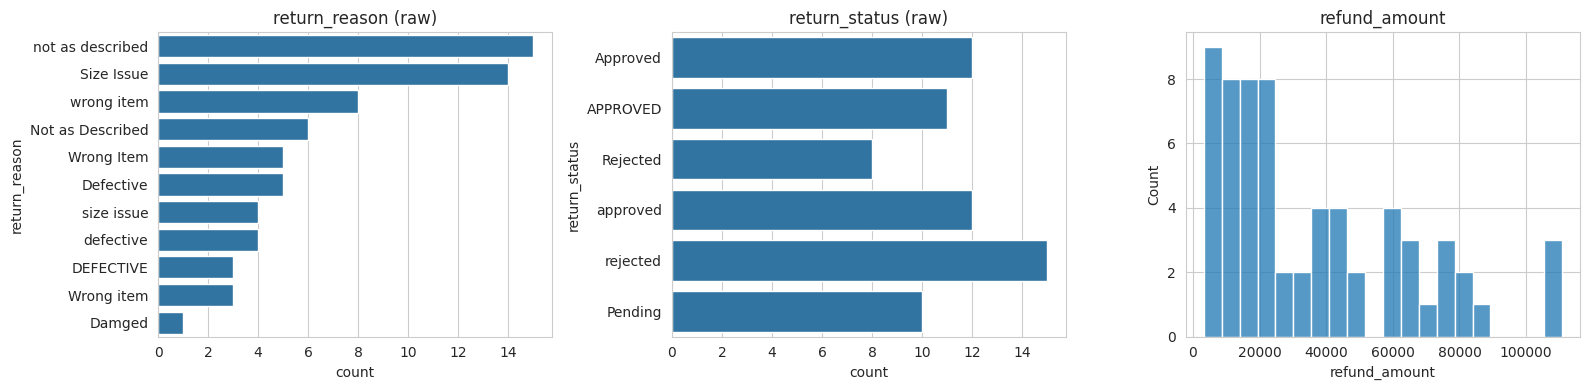

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, y='return_reason', order=df['return_reason'].value_counts().index, ax=ax[0])
sns.countplot(data=df, y='return_status', ax=ax[1])
sns.histplot(df['refund_amount'].dropna(), bins=20, ax=ax[2])
ax[0].set_title('return_reason (raw)')
ax[1].set_title('return_status (raw)')
ax[2].set_title('refund_amount')
plt.tight_layout()
plt.show()

In [10]:
items = pd.read_csv('order_items_clean.csv')
orders = pd.read_csv('orders_clean.csv', parse_dates=['order_date'])
print(sorted(set(df['order_item_id']) - set(items['order_item_id'])))

['OI903929', 'OI914338', 'OI921282', 'OI923804', 'OI947850', 'OI987643']


In [11]:
def parse_date(x):
    if pd.isna(x):
        return pd.NaT
    x = str(x).strip()
    if x == '' or x.lower() == 'unknown':
        return pd.NaT
    if '/' in x:
        a, b, c = [int(i) for i in x.split('/')]
        if a > 12:
            return pd.Timestamp(year=c, month=b, day=a)
        if b > 12:
            return pd.Timestamp(year=c, month=a, day=b)
        return pd.Timestamp(year=c, month=b, day=a)
    if len(x) == 10 and x[4] == '-':
        return pd.to_datetime(x, format='%Y-%m-%d')
    return pd.to_datetime(x, format='%d-%b-%Y')


def is_ambiguous(x):
    if pd.isna(x) or '/' not in str(x):
        return False
    a, b, c = [int(i) for i in str(x).split('/')]
    return a <= 12 and b <= 12 and a != b

In [12]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(before, '->', len(df))
print(df['return_id'].duplicated().sum())

68 -> 65
0


In [13]:
reason_map = {'not as described': 'Not as Described', 'size issue': 'Size Issue',
              'wrong item': 'Wrong Item', 'defective': 'Defective', 'damged': 'Damaged'}
df['return_reason'] = df['return_reason'].str.strip().str.lower().map(reason_map)
print(df['return_reason'].isnull().sum())
df['return_reason'].value_counts()

0


return_reason
Not as Described    19
Size Issue          17
Wrong Item          16
Defective           12
Damaged              1
Name: count, dtype: int64

In [14]:
df['return_status'] = df['return_status'].str.strip().str.title()
df['return_status'].value_counts()

return_status
Approved    32
Rejected    23
Pending     10
Name: count, dtype: int64

In [15]:
df['return_ambiguous'] = df['return_date'].apply(is_ambiguous)
df['return_date'] = df['return_date'].apply(parse_date)
print(df['return_ambiguous'].sum())
df['return_date'].describe()

9


count                            65
mean     2024-11-10 02:35:04.615384
min             2023-01-01 00:00:00
25%             2024-06-04 00:00:00
50%             2024-12-08 00:00:00
75%             2025-07-11 00:00:00
max             2025-12-11 00:00:00
Name: return_date, dtype: object

In [16]:
df['refund_missing'] = df['refund_amount'].isnull()
df[df['refund_missing']]

,return_id,order_item_id,return_date,return_reason,refund_amount,return_status,return_ambiguous,refund_missing
4,R0053,OI000045,2024-03-21,Wrong Item,NaN,Approved,False,True
8,R0005,OI000302,2024-09-26,Size Issue,NaN,Rejected,False,True
10,R0019,OI000301,2025-01-14,Not as Described,NaN,Pending,False,True
60,R0061,OI000502,2024-10-30,Size Issue,NaN,Rejected,False,True


In [17]:
df['item_orphan'] = ~df['order_item_id'].isin(items['order_item_id'])
print(df['item_orphan'].sum())
df[df['item_orphan']]

6


,return_id,order_item_id,return_date,return_reason,refund_amount,return_status,return_ambiguous,refund_missing,item_orphan
7,R0060,OI947850,2024-10-08,Size Issue,70544.98,Approved,False,False,True
11,R0048,OI903929,2025-09-30,Not as Described,22567.44,Approved,False,False,True
18,R0034,OI914338,2024-08-13,Size Issue,13951.03,Approved,False,False,True
25,R0023,OI987643,2025-03-25,Size Issue,109605.02,Pending,False,False,True
30,R0010,OI921282,2024-10-06,Not as Described,11574.32,Approved,True,False,True
33,R0065,OI923804,2024-07-06,Not as Described,17052.06,Rejected,False,False,True


In [18]:
df = df.merge(items[['order_item_id', 'order_id', 'quantity', 'line_total']], on='order_item_id', how='left')
df = df.merge(orders[['order_id', 'order_date', 'order_status']], on='order_id', how='left')
df['refund_exceeds_line'] = df['refund_amount'] > df['line_total']
df['return_before_order'] = df['return_date'] < df['order_date']
print(df['refund_exceeds_line'].sum(), df['return_before_order'].sum())
df[df['refund_exceeds_line']][['return_id', 'order_item_id', 'refund_amount', 'line_total', 'return_status']]

4 31


,return_id,order_item_id,refund_amount,line_total,return_status
40,R0040,OI000018,108702.96,80021.12,Approved
52,R0052,OI000210,8184.16,5439.87,Rejected
54,R0064,OI000697,36219.09,21210.63,Approved
58,R0027,OI000658,20843.86,15850.08,Pending


In [19]:
df['refund_ratio'] = (df['refund_amount'] / df['line_total']).round(3)
df.groupby('return_status')['refund_ratio'].describe()

,count,mean,std,min,25%,50%,75%,max
return_status,,,,,,,,
Approved,27.0,0.961519,0.179846,0.828,0.86650,0.9250,0.97100,1.708
Pending,8.0,0.978250,0.150230,0.849,0.86350,0.9700,0.99750,1.315
Rejected,20.0,0.931100,0.147109,0.805,0.84575,0.9095,0.95375,1.504


In [20]:
df[(df['return_status'] == 'Rejected') & df['refund_amount'].notna()].shape

(21, 17)

In [21]:
df['refund_payable'] = df['refund_amount'].where(df['return_status'] == 'Approved', 0)
df.groupby('return_status')['refund_payable'].sum()

return_status
Approved    1229041.53
Pending           0.00
Rejected          0.00
Name: refund_payable, dtype: float64

In [22]:
df = df.drop(columns=['order_date'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   return_id            65 non-null     str           
 1   order_item_id        65 non-null     str           
 2   return_date          65 non-null     datetime64[us]
 3   return_reason        65 non-null     str           
 4   refund_amount        61 non-null     float64       
 5   return_status        65 non-null     str           
 6   return_ambiguous     65 non-null     bool          
 7   refund_missing       65 non-null     bool          
 8   item_orphan          65 non-null     bool          
 9   order_id             59 non-null     str           
 10  quantity             59 non-null     float64       
 11  line_total           59 non-null     float64       
 12  order_status         59 non-null     str           
 13  refund_exceeds_line  65 non-null     bool       

In [23]:
df.isnull().sum()

return_id               0
order_item_id           0
return_date             0
return_reason           0
refund_amount           4
return_status           0
return_ambiguous        0
refund_missing          0
item_orphan             0
order_id                6
quantity                6
line_total              6
order_status            6
refund_exceeds_line     0
return_before_order     0
refund_ratio           10
refund_payable          1
dtype: int64

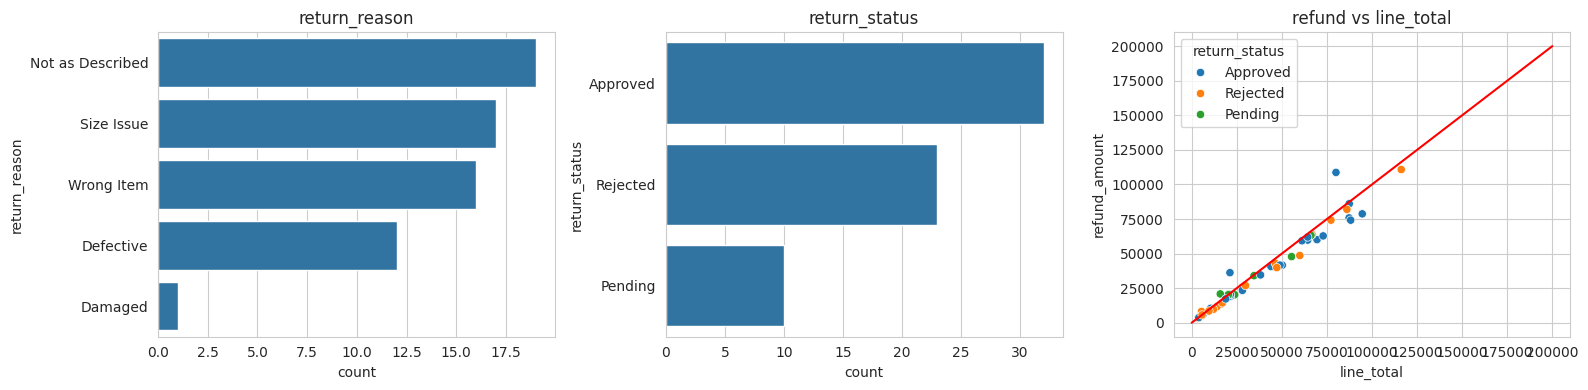

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, y='return_reason', order=df['return_reason'].value_counts().index, ax=ax[0])
sns.countplot(data=df, y='return_status', ax=ax[1])
sns.scatterplot(data=df, x='line_total', y='refund_amount', hue='return_status', ax=ax[2])
ax[2].plot([0, 200000], [0, 200000], color='red')
ax[0].set_title('return_reason')
ax[1].set_title('return_status')
ax[2].set_title('refund vs line_total')
plt.tight_layout()
plt.show()

In [25]:
pd.crosstab(df['return_reason'], df['return_status'])

return_status,Approved,Pending,Rejected
return_reason,,,
Damaged,0,0,1
Defective,8,1,3
Not as Described,12,3,4
Size Issue,7,3,7
Wrong Item,5,3,8


In [26]:
df.to_csv('returns_clean.csv', index=False)
df.head()

,return_id,order_item_id,return_date,return_reason,refund_amount,return_status,return_ambiguous,refund_missing,item_orphan,order_id,quantity,line_total,order_status,refund_exceeds_line,return_before_order,refund_ratio,refund_payable
0,R0018,OI000526,2024-01-21,Wrong Item,18739.92,Approved,False,False,False,O00111,5.0,19389.26,Completed,False,True,0.967,18739.92
1,R0045,OI000620,2025-12-11,Size Issue,6474.73,Approved,True,False,False,O00320,4.0,6615.99,Completed,False,False,0.979,6474.73
2,R0044,OI000640,2024-04-02,Wrong Item,25783.29,Rejected,False,False,False,O00176,2.0,28120.82,Completed,False,True,0.917,0.00
3,R0002,OI000546,2024-06-18,Not as Described,18753.51,Approved,False,False,False,O00145,1.0,19264.95,Completed,False,True,0.973,18753.51
4,R0053,OI000045,2024-03-21,Wrong Item,NaN,Approved,False,True,False,O00174,5.0,15127.85,Returned,False,True,NaN,NaN
